In [2]:
import requests
import pandas as pd

# 1. Alamat sumber data prakiraan Gambir
url = "https://api.bmkg.go.id/publik/prakiraan-cuaca?adm4=31.71.01.1001"

# 2. Mengambil data dari BMKG
respons = requests.get(url, timeout=30)
print("Status akses:", respons.status_code)
respons.raise_for_status()

# 3. Membaca data JSON
data = respons.json()

# 4. Mengumpulkan setiap catatan prakiraan
daftar_cuaca = []

for lokasi in data["data"]:
    for kelompok_waktu in lokasi["cuaca"]:
        for catatan in kelompok_waktu:
            daftar_cuaca.append(catatan)

if not daftar_cuaca:
    raise ValueError("Data prakiraan kosong.")

# 5. Membuat tabel dan memilih kolom yang dibutuhkan
tabel = pd.DataFrame(daftar_cuaca)

tabel = tabel[
    ["local_datetime", "t", "hu", "ws", "weather_desc"]
].copy()

# 6. Mengganti nama kolom supaya mudah dibaca
tabel.columns = [
    "Waktu Prakiraan WIB",
    "Suhu (°C)",
    "Kelembapan (%)",
    "Kecepatan Angin (km/jam)",
    "Kondisi Cuaca"
]

# 7. Menampilkan hasil
print("Jumlah catatan:", len(tabel))
display(tabel)

Status akses: 200
Jumlah catatan: 17


,Waktu Prakiraan WIB,Suhu (°C),Kelembapan (%),Kecepatan Angin (km/jam),Kondisi Cuaca
0,2026-11-18 21:00:00,25,92,3.9,Hujan Ringan
1,2026-11-19 00:00:00,25,94,1.7,Berawan
2,2026-11-19 03:00:00,24,95,2.7,Hujan Ringan
3,2026-11-19 06:00:00,25,94,1.6,Cerah
4,2026-11-19 09:00:00,28,76,2.5,Cerah
5,2026-11-19 12:00:00,30,74,10.2,Hujan Ringan
6,2026-11-19 15:00:00,28,77,3.8,Hujan Ringan
7,2026-11-19 18:00:00,26,88,4.4,Hujan Ringan
8,2026-11-19 21:00:00,26,91,3.9,Cerah Berawan
9,2026-11-20 00:00:00,25,93,1.0,Berawan


In [3]:
from google.colab import files
from datetime import datetime
from zoneinfo import ZoneInfo

# Waktu penyimpanan untuk membedakan setiap file
waktu_simpan = datetime.now(
    ZoneInfo("Asia/Jakarta")
).strftime("%Y%m%d_%H%M%S")

nama_file = f"prakiraan_bmkg_gambir_{waktu_simpan}.csv"

# Simpan tabel tanpa nomor indeks di sebelah kiri
tabel.to_csv(nama_file, index=False, encoding="utf-8-sig")

# Unduh file ke komputer
files.download(nama_file)

print("File berhasil disimpan:", nama_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File berhasil disimpan: prakiraan_bmkg_gambir_20261118_210531.csv


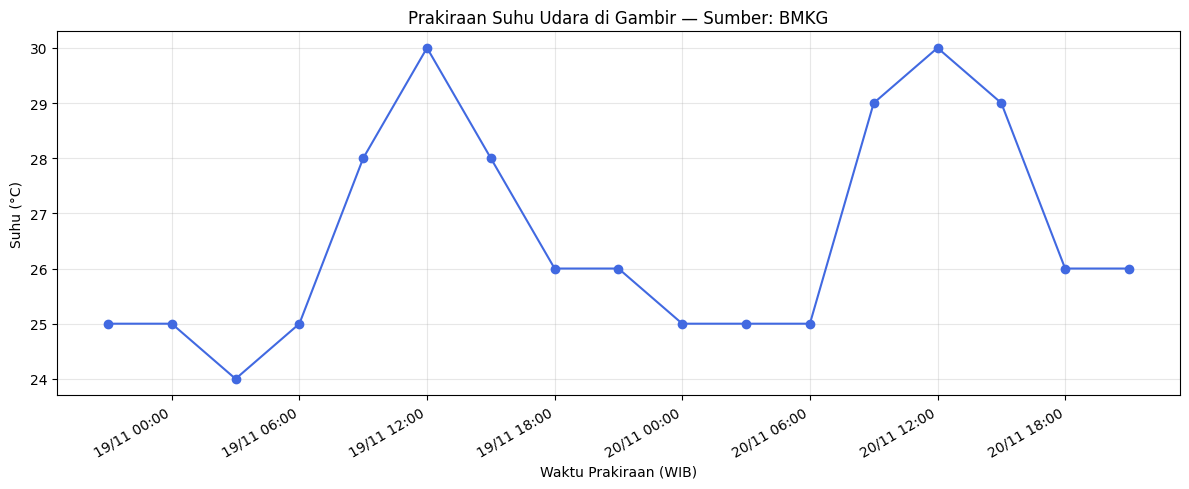

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Salin tabel agar tabel awal tetap tersedia
grafik = tabel.copy()

# Ubah teks waktu menjadi tipe tanggal dan waktu
grafik["Waktu Prakiraan WIB"] = pd.to_datetime(
    grafik["Waktu Prakiraan WIB"]
)

# Urutkan dari waktu paling awal
grafik = grafik.sort_values("Waktu Prakiraan WIB")

# Buat grafik
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    grafik["Waktu Prakiraan WIB"],
    grafik["Suhu (°C)"],
    marker="o",
    color="royalblue"
)

ax.set_title("Prakiraan Suhu Udara di Gambir — Sumber: BMKG")
ax.set_xlabel("Waktu Prakiraan (WIB)")
ax.set_ylabel("Suhu (°C)")
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m %H:%M")
)
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [5]:
# Pilih tiga indikator yang akan dianalisis
kolom_indikator = [
    "Suhu (°C)",
    "Kelembapan (%)",
    "Kecepatan Angin (km/jam)"
]

# Pastikan nilainya berupa angka
angka = tabel[kolom_indikator].apply(
    pd.to_numeric, errors="coerce"
)

# Periksa nilai kosong atau yang gagal dibaca sebagai angka
print("Jumlah nilai kosong per indikator:")
display(angka.isna().sum().to_frame("Jumlah kosong"))

# Hitung ringkasan statistik
ringkasan = angka.agg(["count", "min", "max", "mean"]).T

ringkasan.columns = [
    "Jumlah Data Valid",
    "Minimum",
    "Maksimum",
    "Rata-rata"
]

display(ringkasan.round(2))

Jumlah nilai kosong per indikator:


,Jumlah kosong
Suhu (°C),0
Kelembapan (%),0
Kecepatan Angin (km/jam),0


,Jumlah Data Valid,Minimum,Maksimum,Rata-rata
Suhu (°C),17.0,24.0,30.0,26.59
Kelembapan (%),17.0,74.0,95.0,86.06
Kecepatan Angin (km/jam),17.0,1.0,10.2,3.48


**Analisis Awal Data Prakiraan Cuaca Gambir**

Berdasarkan data prakiraan BMKG untuk Kelurahan Gambir pada periode 18 November 2026 pukul 21.00 hingga 20 November 2026 pukul 21.00 WIB, terdapat 17 catatan prakiraan. Pemeriksaan pada indikator suhu, kelembapan, dan kecepatan angin tidak menemukan nilai kosong.

Suhu diprakirakan berkisar antara 24–30 °C dengan rata-rata 26,59 °C. Kelembapan diprakirakan berada pada rentang 74–95% dengan rata-rata 86,06%. Sementara itu, kecepatan angin diprakirakan berkisar antara 1–10,2 km/jam dengan rata-rata 3,48 km/jam.

Ringkasan tersebut dihitung dari seluruh catatan waktu prakiraan yang tersedia, bukan rata-rata harian. Hasil ini menggambarkan prakiraan BMKG, bukan pengukuran cuaca aktual, sehingga belum dapat digunakan untuk menyimpulkan akurasi prakiraan maupun tren iklim jangka panjang.

Sumber data: BMKG, https://data.bmkg.go.id/prakiraan-cuaca/